In [1]:
from mercupix.ramp import RawRamp
from mercupix.rampfit import fit_ramp, Kubik2015
from mercupix.image import FluxMap
import matplotlib.pyplot as plt
import numpy as np

### Read raw ramp and "process"

In [ ]:
path_to_h5 = '/Users/marieaubert/Lazuli/data/'
ramp = RawRamp.from_filename(filename='1739179234.69-20250213_04h31_11-one_ramp-asic_01-acq.h5',
                  frame_path='/run/seq_1/asic_1/ramp_1/frames',
                   time_arr_path='/run/seq_1/env_measures/')

# To be tested with Roman triplet data as well. Some header measurement needed mostlikely.

Plot : 

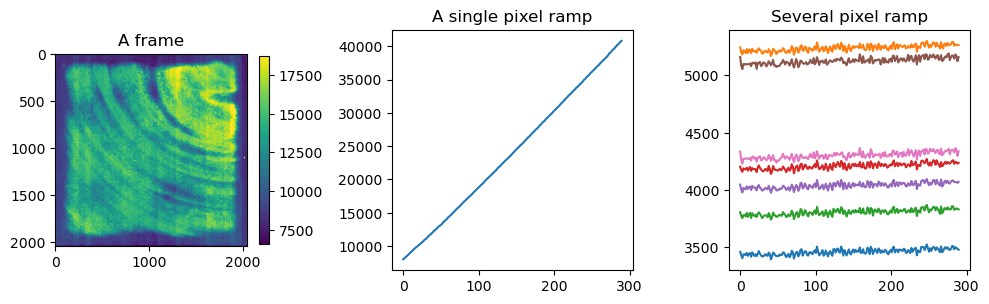

In [3]:
fig, axs = plt.subplots(1,3, figsize=(10,5), subplot_kw=dict(box_aspect=1))
axs[0].set_title('A frame')
fig = ramp.show_frame(frame_num=3, fig=fig, ax=axs[0]) # Frame to be chosen, default to 0
axs[1].set_title('A single pixel ramp')
fig = ramp.show_pixramp(pixel_num=2040*10, fig=fig, ax=axs[1])  # Example get one ramp for a single pixel. 
axs[2].set_title('Several pixel ramp')
fig = ramp.show_pixramp(pixel_num=slice(1403, 1410), fig=fig, ax=axs[2])  # Example get one ramp for several pixel. 
# Small issue with axes sizes.
plt.tight_layout()
plt.show()

Plot :  With refpix correction 

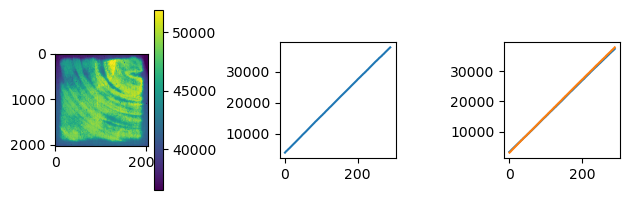

In [4]:
fig, axs = plt.subplots(1,3, subplot_kw=dict(box_aspect=1))
fig = ramp.show_frame(frame_num=-1, fig=fig, ax=axs[0], corr_refpix=True) # Frame to be chosen, default to 0
fig = ramp.show_pixramp(pixel_num=2040*10, fig=fig, ax=axs[1], corr_refpix=True)  # Example get one ramp for a single pixel. 
fig = ramp.show_pixramp(pixel_num=slice(4,6), fig=fig, ax=axs[2], corr_refpix=True)  # Example get one ramp for several pixel. 
# Small issue with axes sizes.
plt.tight_layout()
plt.show()

Fit ramp with chosen procedure : 
kwargs will depend on procedure (readnoise and gain can be plugged for Kubik for example) 

In [5]:
datacube, varcube = ramp.preprocess_ramp()

In [6]:
ramp.t_read.shape

(200,)

In [28]:
slope_lsq_leg = fit_ramp(datacube=datacube, 
                         time_frames=ramp.t_read,
                         fit_args=dict(deg=3), 
                         polytype='leg').reshape(2040,2040) # Using ref-corrected pixels only 'scicube'

In [29]:
slope_lsq = fit_ramp(datacube=datacube, 
                     fit_args=dict(deg=3),
                     time_frames=ramp.t_read,
                     polytype='mono').reshape(2040,2040) #  Using ref-corrected pixels only 'scicube'


In [30]:
slope_kbk = fit_ramp(datacube=datacube, 
                     method='Kubik', 
                     time_frames=ramp.t_read)/np.diff(ramp.t_read)[0] #For OK units. Kubik works at the delta-group level. 


### Store output in SciExposure 
Name will probably change but should be the output with I/O

In [ ]:
lsq_leg_img = FluxMap(data=slope_lsq_leg)
lsq_img = FluxMap(data=slope_lsq)
kbk_img = FluxMap(data=slope_kbk)
a

Plot : 

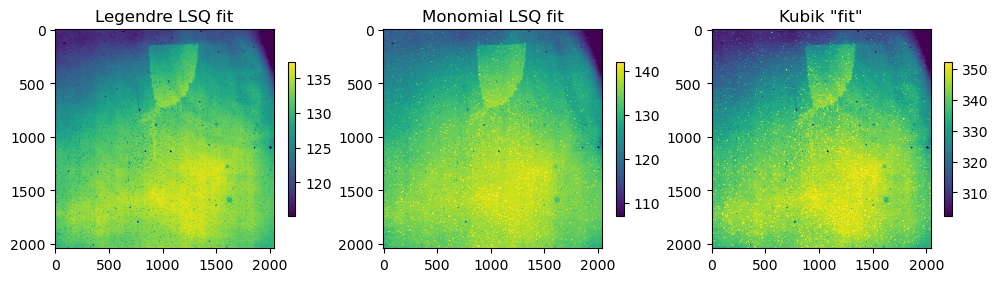

In [114]:
fig, axs = plt.subplots(1,3, figsize=(12,5))
axs[0].set_title('Legendre LSQ fit')
lsq_leg_img.show(ax=axs[0])
axs[1].set_title('Monomial LSQ fit')
lsq_img.show(ax=axs[1])
axs[2].set_title('Kubik "fit"')
kbk_img.show(ax=axs[2])
plt.show()

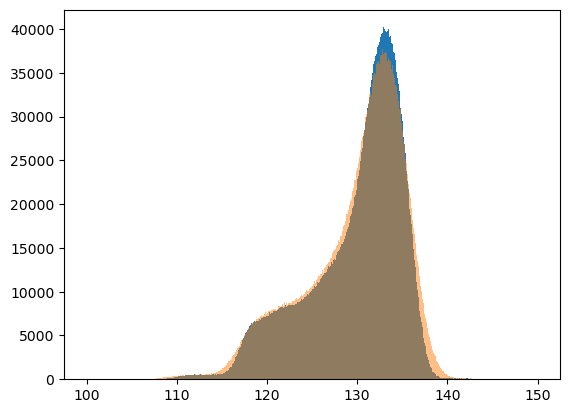

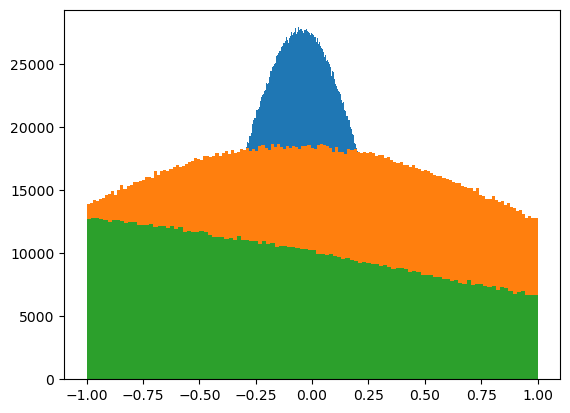

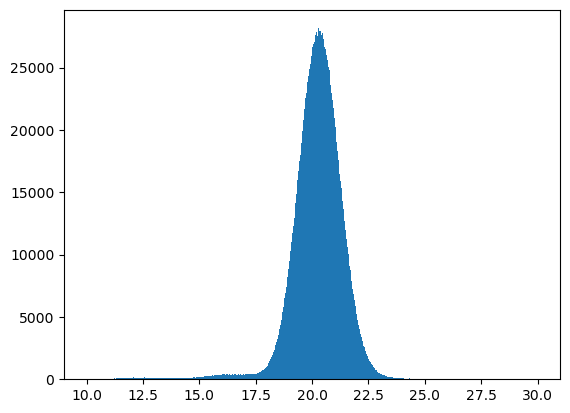

In [49]:
plt.figure()
plt.hist(np.ravel(np.mean(np.diff(datacube, axis=0)/np.diff(ramp.t_read)[:,None,None], axis=0)), bins='fd', range=[100, 150])
plt.hist(np.ravel(np.median(np.diff(datacube, axis=0)/np.diff(ramp.t_read)[:,None,None], axis=0)), bins='fd', range=[100, 150], alpha=0.5)
plt.show()


plt.figure()
plt.hist(np.ravel(np.mean(np.diff(datacube, axis=0)/np.diff(ramp.t_read)[:,None,None],axis=0) - slope_lsq_leg),bins='fd', range=[-1,1])
plt.hist(np.ravel(np.median(np.diff(datacube, axis=0)/np.diff(ramp.t_read)[:,None,None],axis=0) - slope_lsq_leg),bins='fd', range=[-1,1])
plt.hist(np.ravel(np.mean(np.diff(datacube, axis=0)/np.diff(ramp.t_read)[:,None,None],axis=0) - slope_lsq),bins='fd', range=[-1,1])
plt.hist(np.ravel(np.mean(np.diff(datacube, axis=0)/np.diff(ramp.t_read)[:,None,None],axis=0) - slope_kbk),bins='fd', range=[-1,1])
plt.show()


plt.figure()
plt.hist(np.ravel(np.std(np.diff(datacube, axis=0)/np.diff(ramp.t_read)[:,None,None], axis=0, ddof=1)), bins='fd' , range=[10,30])
plt.show()

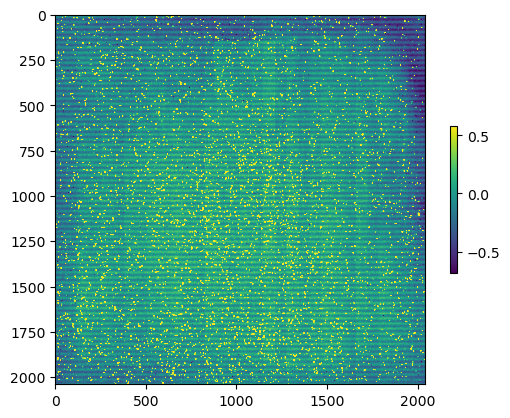

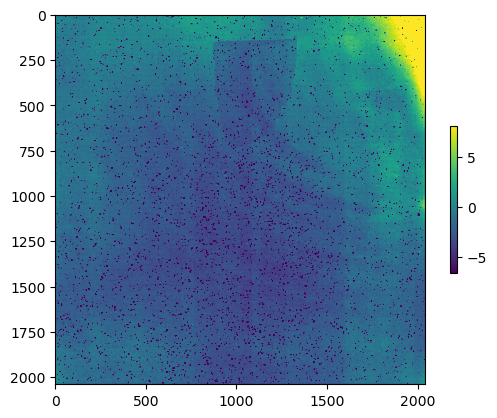

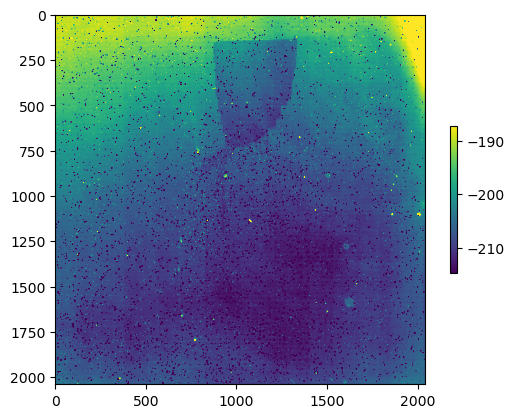

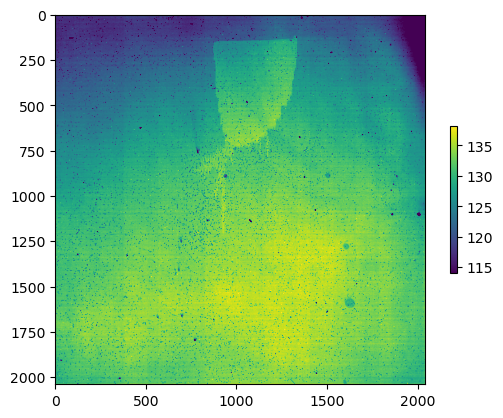

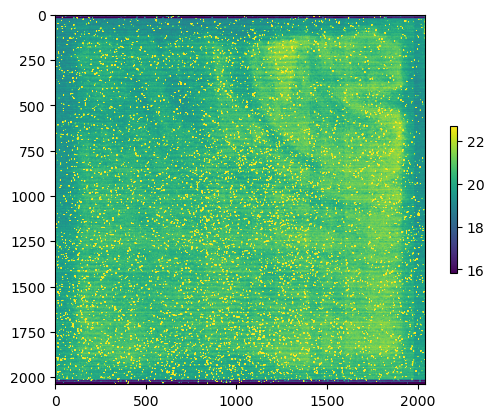

In [ ]:
fig1 = ramp.show_frame(frame=np.mean(np.diff(datacube, axis=0)/np.diff(ramp.t_read)[:,None,None],axis=0) - slope_lsq_leg) 
fig1 = ramp.show_frame(frame=np.mean(np.diff(datacube, axis=0)/np.diff(ramp.t_read)[:,None,None],axis=0)- slope_lsq) 
fig1 = ramp.show_frame(frame=np.mean(np.diff(datacube, axis=0)/np.diff(ramp.t_read)[:,None,None],axis=0) - slope_kbk) 



fig2 = ramp.show_frame(frame=np.median(np.diff(datacube, axis=0)/np.diff(ramp.t_read)[:,None,None], axis=0)) 
fig3 = ramp.show_frame(frame=np.std(np.diff(datacube, axis=0)/np.diff(ramp.t_read)[:,None,None], axis=0, ddof=1)) 
